# ***# STAGE 1: Dataset Understanding***

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("heart_disease_prediction_2026.csv")

print("Shape:", df.shape)
print(df.head())
print(df.info())
print(df.describe().T)

# Target and class distribution
print(df["heart_disease"].value_counts())
print(df["heart_disease"].value_counts(normalize=True) * 100)

# Numerical and categorical columns
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = df.select_dtypes(exclude=["int64", "float64"]).columns.tolist()
print("Numerical:", num_cols)
print("Categorical:", cat_cols)

# Unique values
for col in cat_cols:
    print(col, df[col].unique())

Shape: (67634, 26)
   age     sex   bmi     region income_level smoking_status alcohol_intake  \
0   57    Male  27.1  Northeast       Middle          Never       Moderate   
1   40  Female  29.0  Northeast          Low          Never    Non-drinker   
2   63  Female  40.1  Southeast         High          Never       Moderate   
3   66  Female  35.5       West       Middle          Never          Heavy   
4   29  Female  19.8  Northeast         High        Current    Non-drinker   

  physical_activity  diet_quality  sleep_hours  ...  cholesterol  \
0             Light           7.0          5.7  ...        204.0   
1         Sedentary           1.0          8.0  ...        173.0   
2         Sedentary           6.0          5.5  ...        209.0   
3         Sedentary          10.0          7.4  ...        187.0   
4         Sedentary           8.0          8.3  ...        247.0   

   fasting_blood_sugar  max_heart_rate       resting_ecg  exercise_angina  \
0                  0.0    

# ***STAGE 2: Data Wrangling and Cleaning***

In [2]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check for duplicates
print("Duplicate rows:", df.duplicated().sum())

# Data types check
print(df.dtypes)

# Invalid values check (physiological range)
print("Age range:", df["age"].min(), df["age"].max())
print("BMI range:", df["bmi"].min(), df["bmi"].max())
print("BP range:", df["resting_bp"].min(), df["resting_bp"].max())
print("Cholesterol range:", df["cholesterol"].min(), df["cholesterol"].max())
print("Max HR range:", df["max_heart_rate"].min(), df["max_heart_rate"].max())
print("Negative st_depression:", (df["st_depression"] < 0).sum())

# Binary columns must only contain 0 or 1
binary_cols = ["diabetes", "hypertension", "family_history", "previous_heart_event",
               "fasting_blood_sugar", "exercise_angina", "heart_disease"]
for col in binary_cols:
    print(col, df[col].unique())

# Check for spelling or spacing issues in categorical features
for col in cat_cols:
    print(col, df[col].value_counts().to_dict())

# Outliers detection (using IQR method) only for counting purposes
for col in ["bmi", "resting_bp", "cholesterol", "max_heart_rate", "st_depression", "hrv_score"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((df[col] < low) | (df[col] > high)).sum()
    print(col, "outliers:", count)

# Decision: missing = 0, duplicates = 0, invalid values = 0.
# Do not delete the outliers because they are medically plausible.

Missing values:
age                     0
sex                     0
bmi                     0
region                  0
income_level            0
smoking_status          1
alcohol_intake          1
physical_activity       1
diet_quality            1
sleep_hours             1
stress_level            1
diabetes                1
hypertension            1
family_history          1
previous_heart_event    1
resting_bp              1
cholesterol             1
fasting_blood_sugar     1
max_heart_rate          1
resting_ecg             1
exercise_angina         1
st_depression           1
st_slope                1
avg_resting_hr          1
hrv_score               1
heart_disease           1
dtype: int64
Duplicate rows: 0
age                       int64
sex                      object
bmi                     float64
region                   object
income_level             object
smoking_status           object
alcohol_intake           object
physical_activity        object
diet_quality         

# ***STAGE 3: EDA***

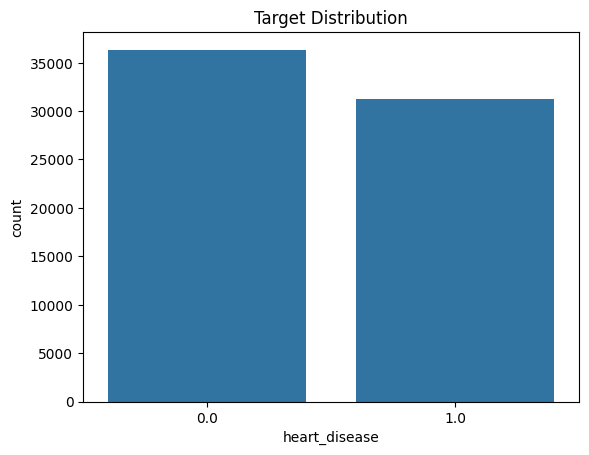

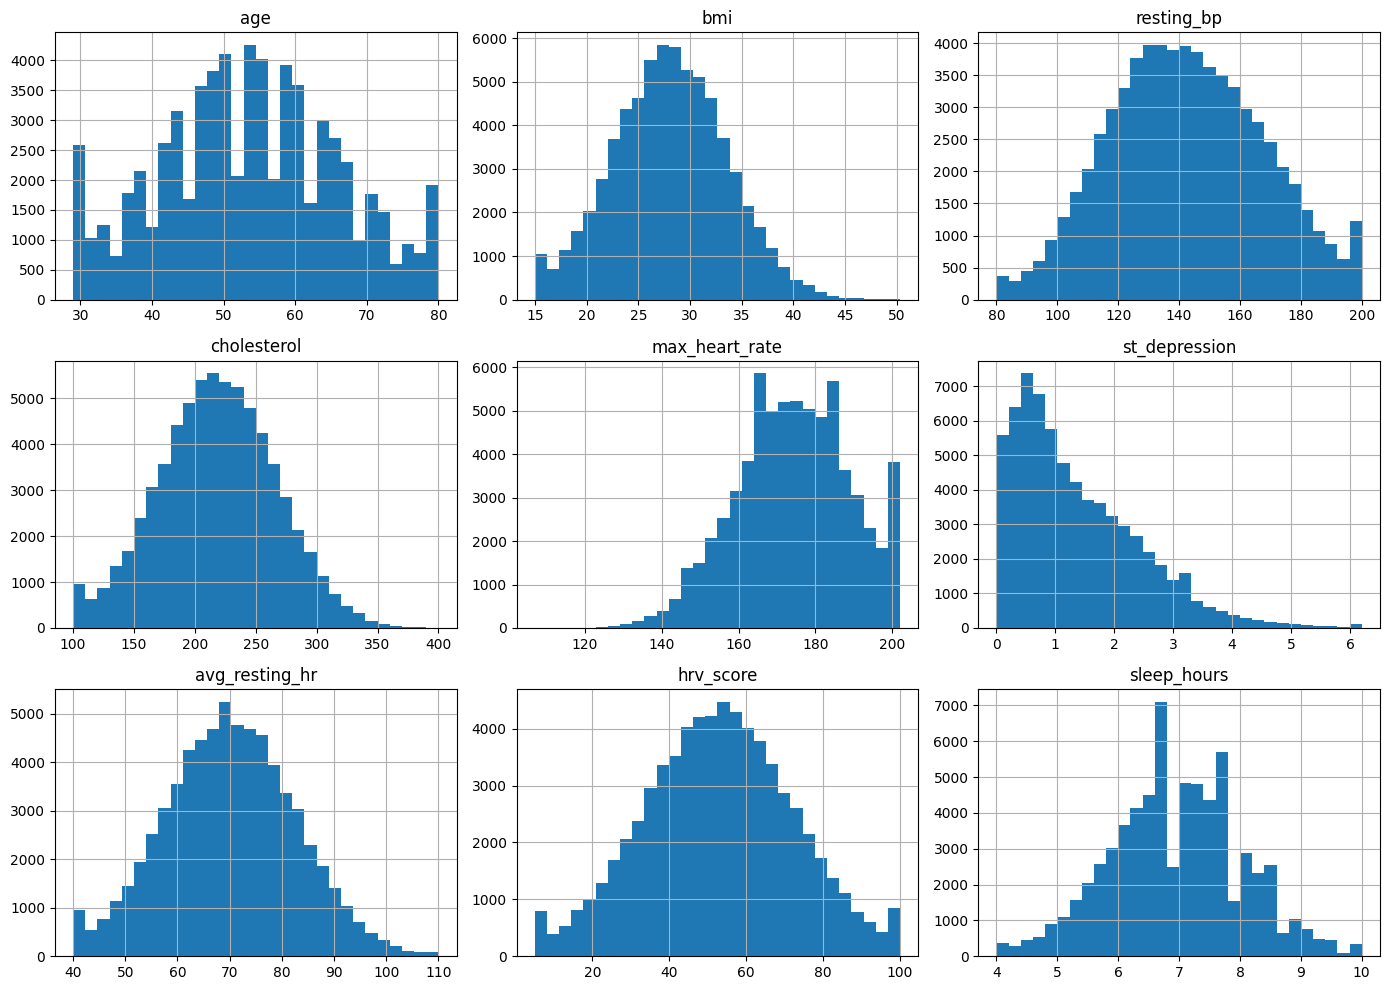

age               0.045773
bmi               0.056889
resting_bp        0.089519
cholesterol       0.005204
max_heart_rate   -0.167380
st_depression     1.148149
avg_resting_hr    0.046785
hrv_score        -0.007571
sleep_hours       0.010905
dtype: float64


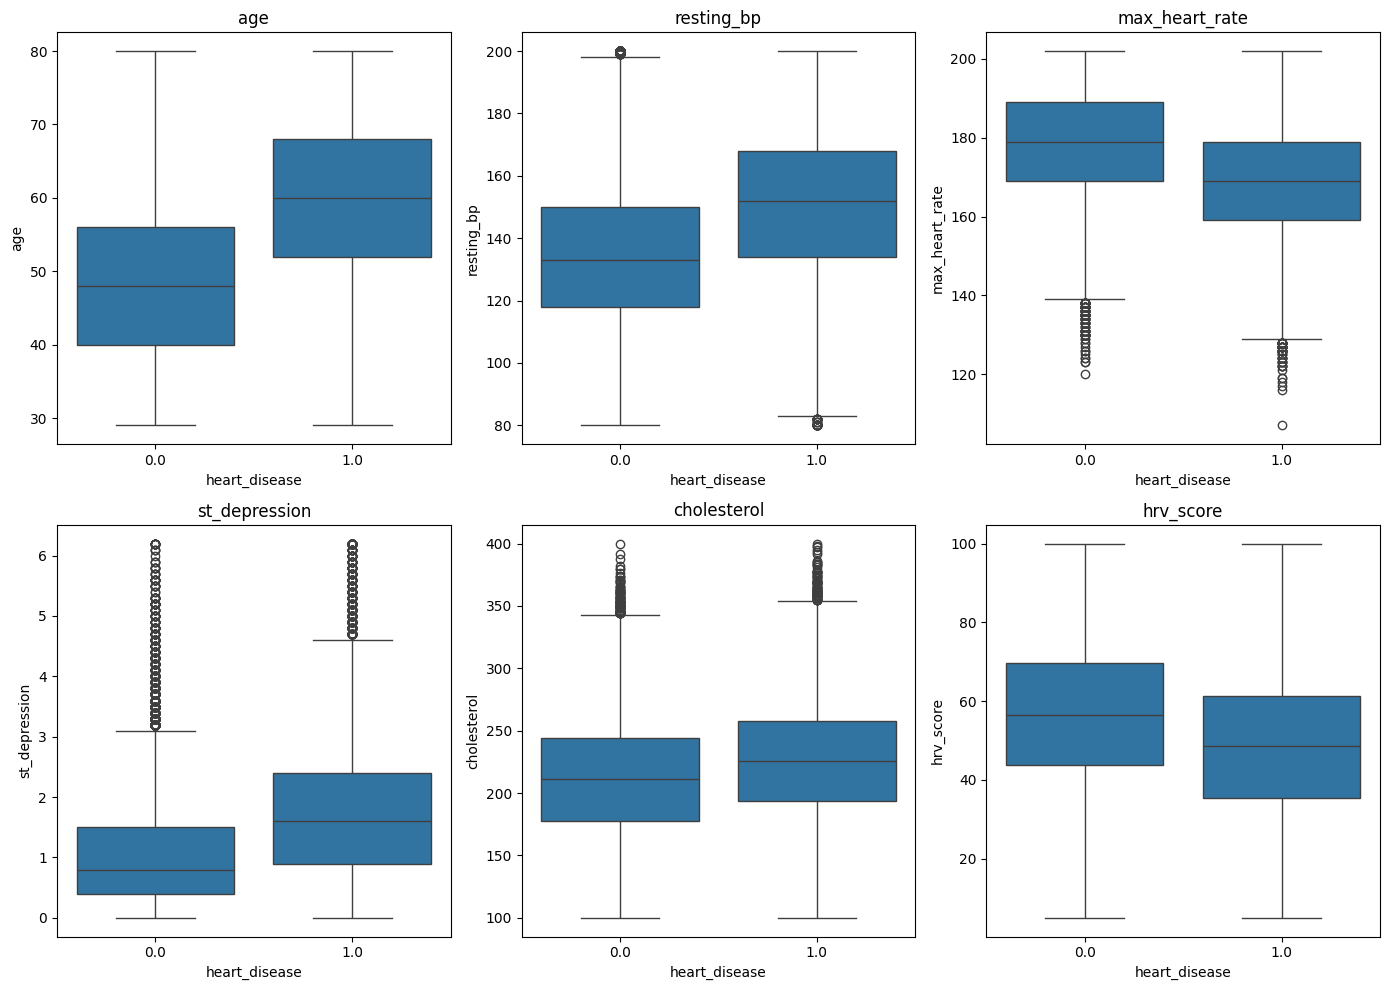

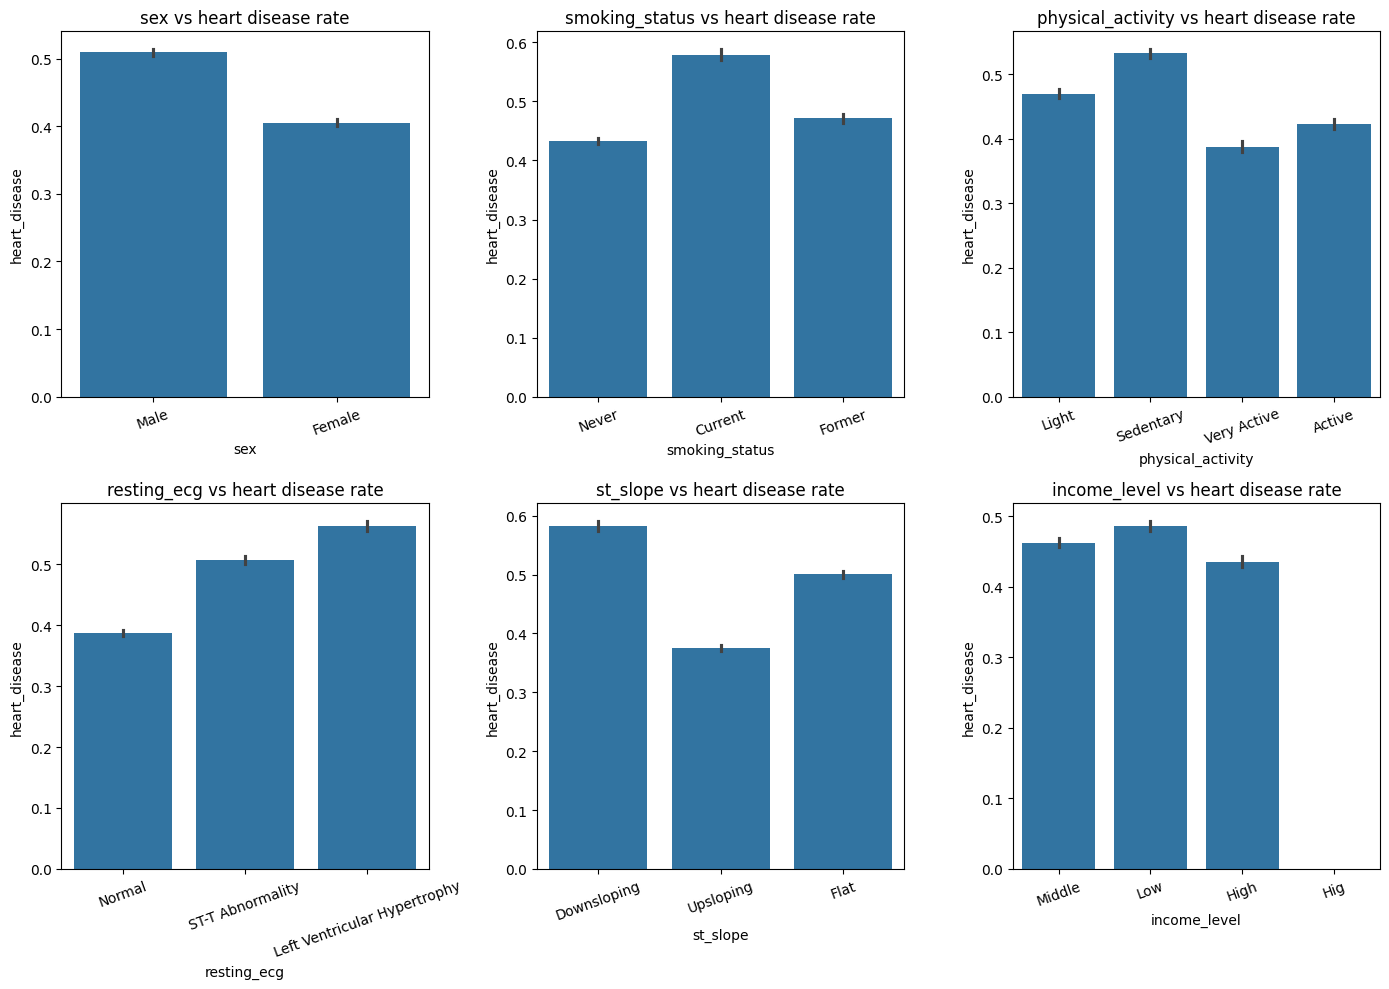

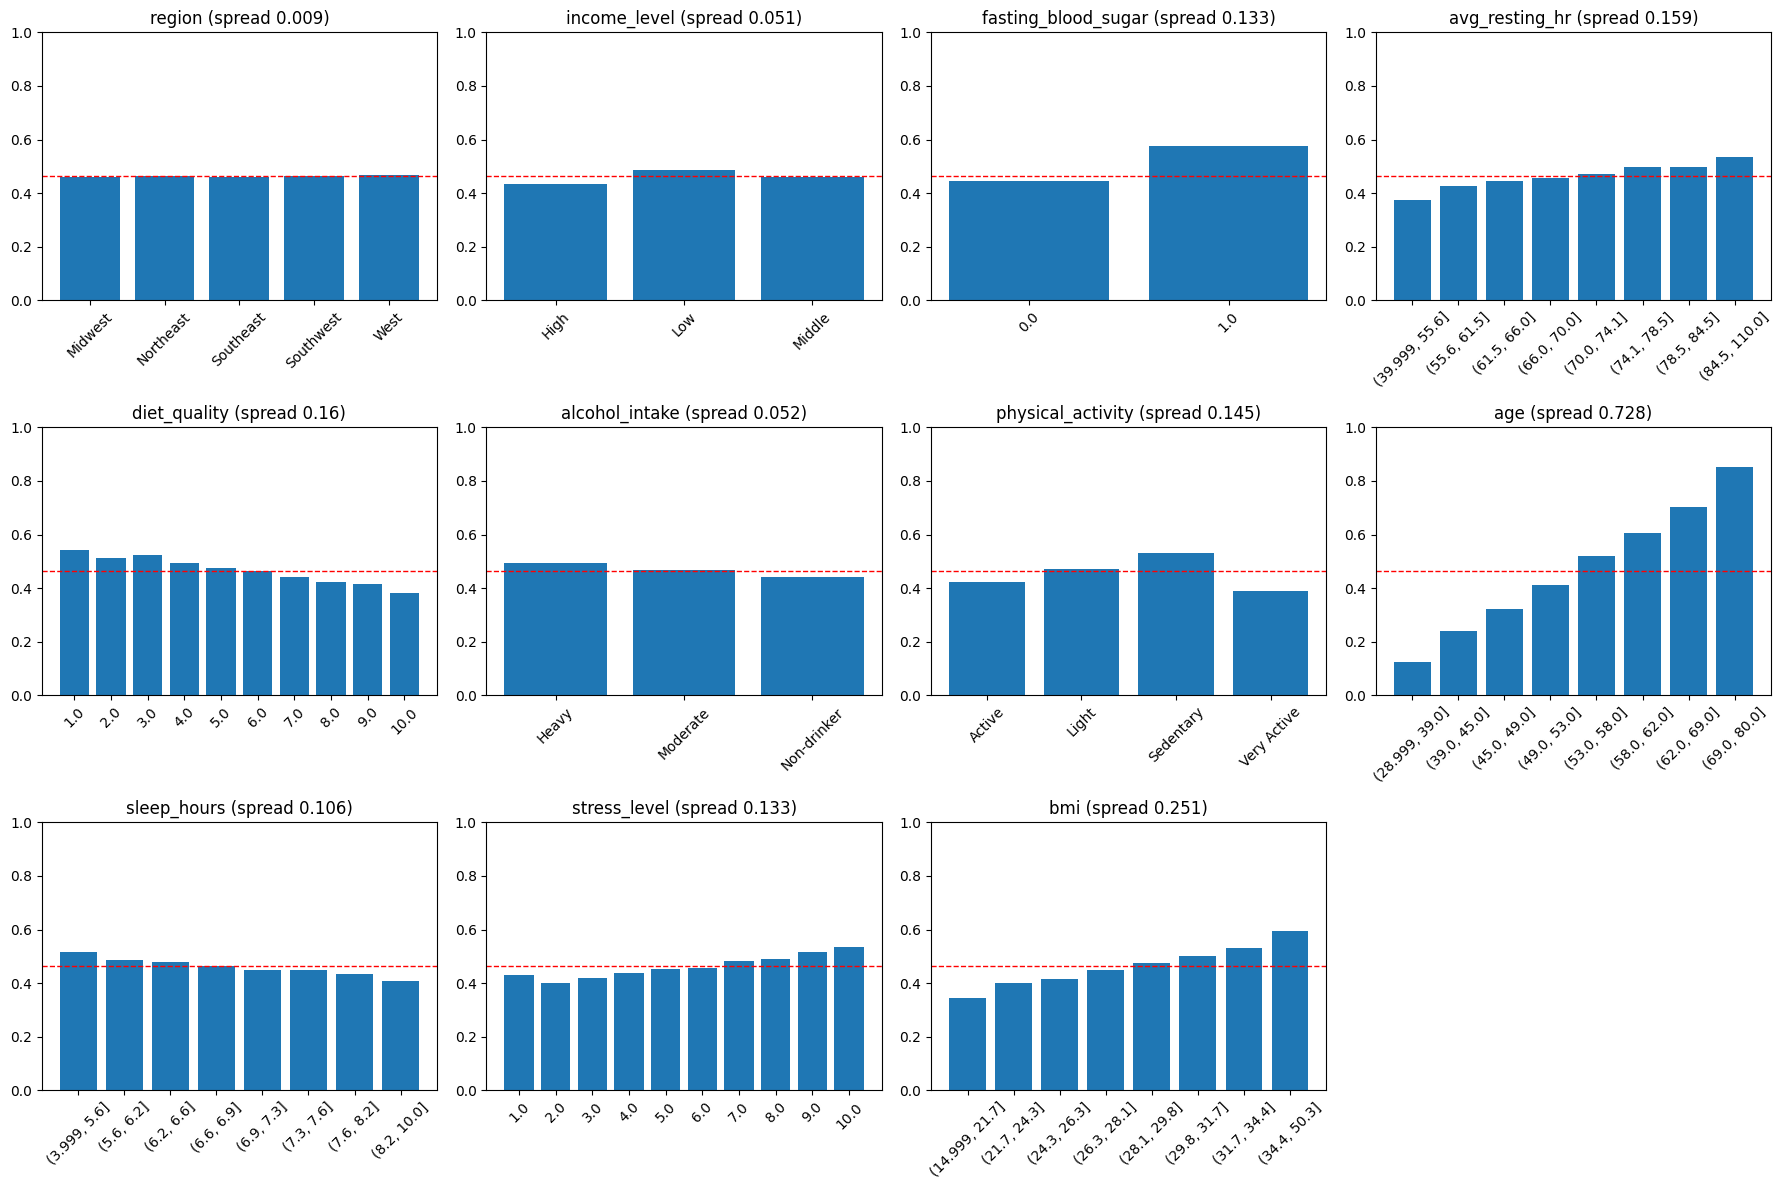

            feature  status  lowest_rate  highest_rate  spread
                age    kept       0.1224        0.8503  0.7279
                bmi    kept       0.3430        0.5942  0.2512
       diet_quality REMOVED       0.3824        0.5419  0.1595
     avg_resting_hr REMOVED       0.3753        0.5338  0.1586
  physical_activity REMOVED       0.3875        0.5326  0.1450
fasting_blood_sugar REMOVED       0.4434        0.5765  0.1331
       stress_level    kept       0.4022        0.5352  0.1330
        sleep_hours    kept       0.4092        0.5156  0.1064
     alcohol_intake REMOVED       0.4425        0.4948  0.0523
       income_level REMOVED       0.4349        0.4860  0.0511
             region REMOVED       0.4585        0.4671  0.0087


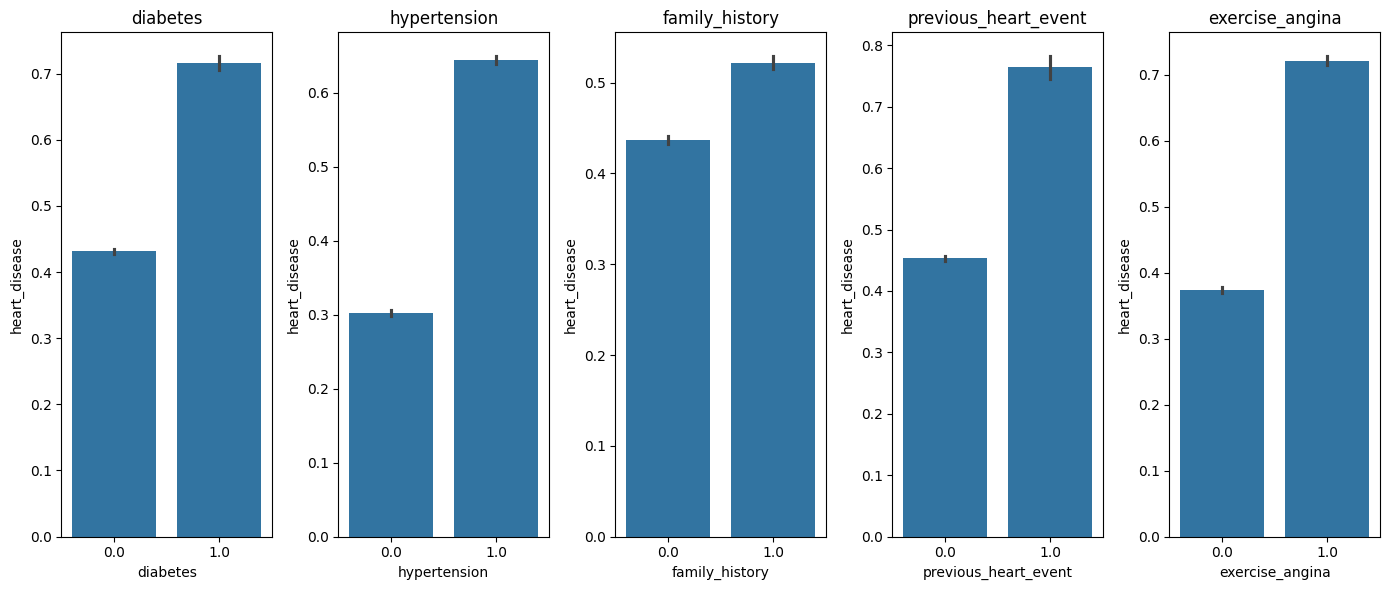

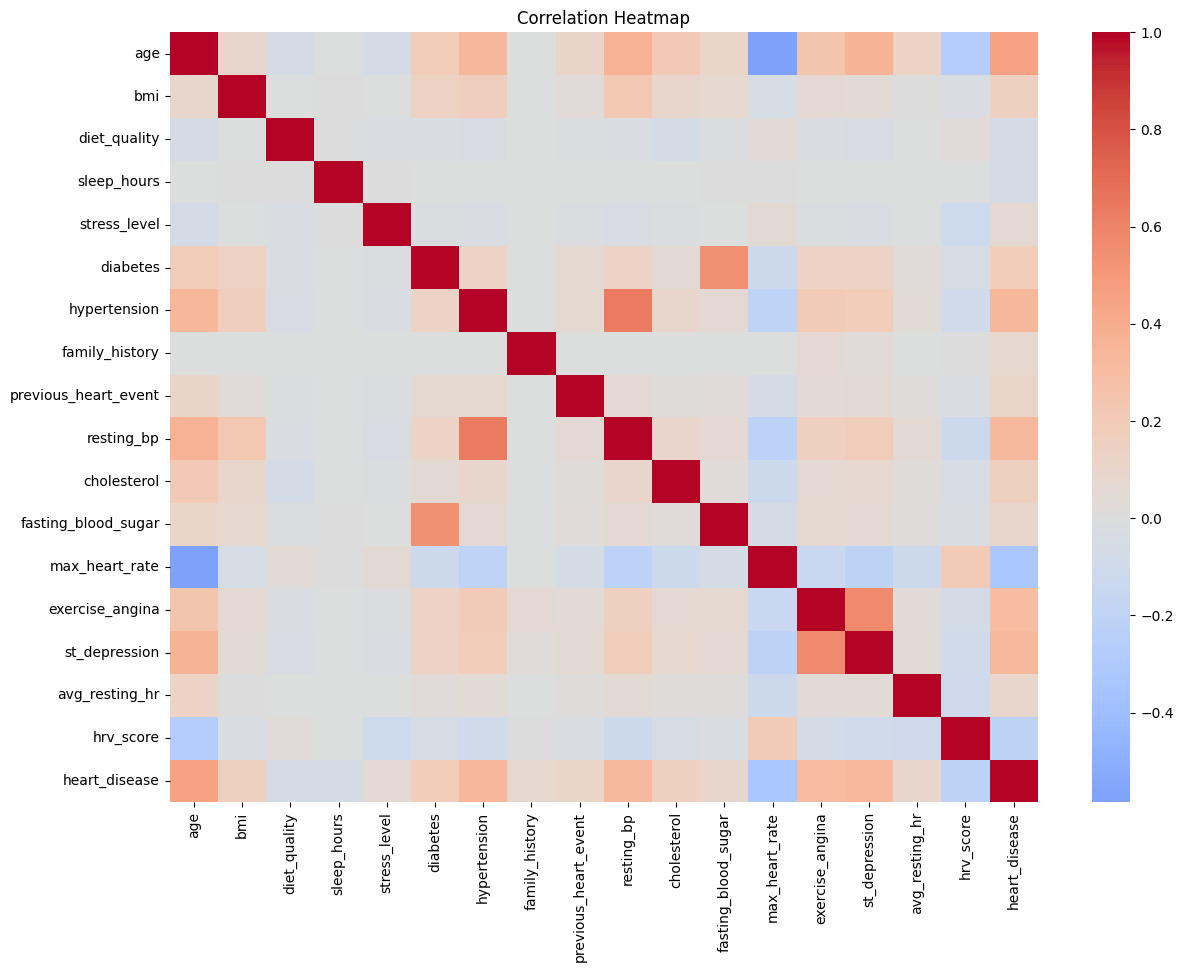

heart_disease           1.000000
age                     0.460225
hypertension            0.341917
st_depression           0.331341
resting_bp              0.324158
exercise_angina         0.304063
diabetes                0.178788
cholesterol             0.151734
bmi                     0.151159
previous_heart_event    0.107265
avg_resting_hr          0.093588
fasting_blood_sugar     0.093572
family_history          0.077535
stress_level            0.063424
sleep_hours            -0.061418
diet_quality           -0.069738
hrv_score              -0.208135
max_heart_rate         -0.319884
Name: heart_disease, dtype: float64
age_group_temp
(0, 40]      0.131393
(40, 50]     0.297507
(50, 60]     0.499380
(60, 70]     0.689469
(70, 100]    0.858591
Name: heart_disease, dtype: float64


In [3]:
# 1. Target distribution
sns.countplot(x="heart_disease", data=df)
plt.title("Target Distribution")
plt.show()

# 2. Distribution of Numerical Features
num_features = ["age", "bmi", "resting_bp", "cholesterol", "max_heart_rate",
                "st_depression", "avg_resting_hr", "hrv_score", "sleep_hours"]
df[num_features].hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

# 3. Skewness
print(df[num_features].skew())

# 4. Boxplots: feature vs target
plt.figure(figsize=(14, 10))
for i, col in enumerate(["age", "resting_bp", "max_heart_rate", "st_depression", "cholesterol", "hrv_score"]):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(x="heart_disease", y=col, data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

# 5. Categorical vs target
plt.figure(figsize=(14, 10))
cat_plot = ["sex", "smoking_status", "physical_activity", "resting_ecg", "st_slope", "income_level"]
for i, col in enumerate(cat_plot):
    plt.subplot(2, 3, i + 1)
    sns.barplot(x=col, y="heart_disease", data=df)
    plt.xticks(rotation=20)
    plt.title(col + " vs heart disease rate")
plt.tight_layout()
plt.show()

# 5B. Heart disease rate for the questioned features, with kept features for comparison
removed_cols = ["region", "income_level", "fasting_blood_sugar", "avg_resting_hr",
                "diet_quality", "alcohol_intake", "physical_activity"]
check_cols = removed_cols + ["age", "sleep_hours", "stress_level", "bmi"]

def rate_by_group(col, n_bins=8):
    s = df[col]
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 10:
        grp = pd.qcut(s, q=n_bins, duplicates="drop")
    else:
        grp = s
    return df.groupby(grp, observed=True)["heart_disease"].mean()

overall = df["heart_disease"].mean()
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
spread_rows = []
for ax, col in zip(axes.ravel(), check_cols):
    rate = rate_by_group(col)
    spread = rate.max() - rate.min()
    ax.bar(rate.index.astype(str), rate.values)
    ax.axhline(overall, color="red", linestyle="--", linewidth=1)
    ax.set_ylim(0, 1)
    ax.set_title(col + " (spread " + str(round(spread, 3)) + ")")
    ax.tick_params(axis="x", rotation=45)
    spread_rows.append({"feature": col,
                        "status": "REMOVED" if col in removed_cols else "kept",
                        "lowest_rate": round(rate.min(), 4),
                        "highest_rate": round(rate.max(), 4),
                        "spread": round(spread, 4)})
for ax in axes.ravel()[len(check_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(pd.DataFrame(spread_rows).sort_values("spread", ascending=False).to_string(index=False))

# 6. Binary features vs target
plt.figure(figsize=(14, 6))
bin_plot = ["diabetes", "hypertension", "family_history", "previous_heart_event", "exercise_angina"]
for i, col in enumerate(bin_plot):
    plt.subplot(1, 5, i + 1)
    sns.barplot(x=col, y="heart_disease", data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

# 7. Correlation heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

# 8. Correlation with the Target
print(df.corr(numeric_only=True)["heart_disease"].sort_values(ascending=False))

# 9. Heart disease rate according to the Ages
df["age_group_temp"] = pd.cut(df["age"], bins=[0, 40, 50, 60, 70, 100])
print(df.groupby("age_group_temp")["heart_disease"].mean())
df = df.drop(columns=["age_group_temp"])

# ***STAGE 4: Feature Engineering and Selection***

In [4]:
print(df[["diabetes", "fasting_blood_sugar"]].corr())
print(df[["hypertension", "resting_bp"]].corr())

# New features
df["age_group"] = pd.cut(df["age"], bins=[0, 40, 50, 60, 70, 100],
                         labels=["under40", "40s", "50s", "60s", "70plus"])
df["age_group"] = df["age_group"].astype(str)

df["bmi_category"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100],
                            labels=["underweight", "normal", "overweight", "obese"])
df["bmi_category"] = df["bmi_category"].astype(str)

# Test: Effect of Region
print(df.groupby("region")["heart_disease"].mean())

# Six weak inputs removed. hr_reserve is omitted because avg_resting_hr is gone.
X = df.drop(columns=["heart_disease", "region", "income_level",
                     "fasting_blood_sugar", "avg_resting_hr", "diet_quality",
                     "alcohol_intake", "physical_activity"])
y = df["heart_disease"]
print(X.shape)
print(X.columns.tolist())

                     diabetes  fasting_blood_sugar
diabetes             1.000000             0.537572
fasting_blood_sugar  0.537572             1.000000
              hypertension  resting_bp
hypertension      1.000000    0.638192
resting_bp        0.638192    1.000000
region
Midwest      0.458471
Northeast    0.463397
Southeast    0.461438
Southwest    0.463563
West         0.467129
Name: heart_disease, dtype: float64
(67634, 20)
['age', 'sex', 'bmi', 'smoking_status', 'sleep_hours', 'stress_level', 'diabetes', 'hypertension', 'family_history', 'previous_heart_event', 'resting_bp', 'cholesterol', 'max_heart_rate', 'resting_ecg', 'exercise_angina', 'st_depression', 'st_slope', 'hrv_score', 'age_group', 'bmi_category']


# ***STAGE 5: Preprocessing***

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

num_features = ["age", "bmi", "sleep_hours", "stress_level",
                "resting_bp", "cholesterol", "max_heart_rate",
                "st_depression", "hrv_score"]

binary_features = ["diabetes", "hypertension", "family_history",
                   "previous_heart_event", "exercise_angina"]

cat_features = ["sex", "smoking_status", "resting_ecg", "st_slope",
                "age_group", "bmi_category"]

# numeric: median imputer + scaling
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# binary: already 0/1, sirf imputer
bin_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

# categorical: most frequent imputer + one hot encoding
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_features),
    ("bin", bin_pipe, binary_features),
    ("cat", cat_pipe, cat_features)
])

# ***STAGE 6: Train-Test Split and Baseline***

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Drop rows where target variable 'heart_disease' is NaN before splitting
df_clean = df.dropna(subset=["heart_disease"])
X_clean = X.loc[df_clean.index]
y_clean = df_clean["heart_disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean)

print("Train:", X_train.shape, "Test:", X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

# Baseline: always predict the majority class
from sklearn.pipeline import Pipeline
dummy = Pipeline([
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_train)
print("Baseline accuracy (train):", accuracy_score(y_train, dummy_pred))
print("Baseline F1:", f1_score(y_train, dummy_pred))

Train: (54106, 20) Test: (13527, 20)
heart_disease
0.0    0.537482
1.0    0.462518
Name: proportion, dtype: float64
heart_disease
0.0    0.537444
1.0    0.462556
Name: proportion, dtype: float64
Baseline accuracy (train): 0.5374819798173954
Baseline F1: 0.0





# ***STAGE 7: Model Training and Comparison ***

Logistic Regression done
Decision Tree done
Random Forest done
LightGBM done
                 Model  roc_auc_mean  roc_auc_std  recall_mean  recall_std  \
0  Logistic Regression        0.8525       0.0021       0.7346      0.0068   
3             LightGBM        0.8481       0.0022       0.7327      0.0071   
2        Random Forest        0.8411       0.0027       0.7170      0.0067   
1        Decision Tree        0.8069       0.0033       0.6906      0.0154   

   precision_mean  precision_std  f1_mean  f1_std  accuracy_mean  accuracy_std  
0          0.7644         0.0044   0.7492  0.0034         0.7725        0.0027  
3          0.7587         0.0051   0.7454  0.0035         0.7685        0.0029  
2          0.7558         0.0049   0.7359  0.0046         0.7620        0.0039  
1          0.7224         0.0071   0.7060  0.0059         0.7340        0.0031  


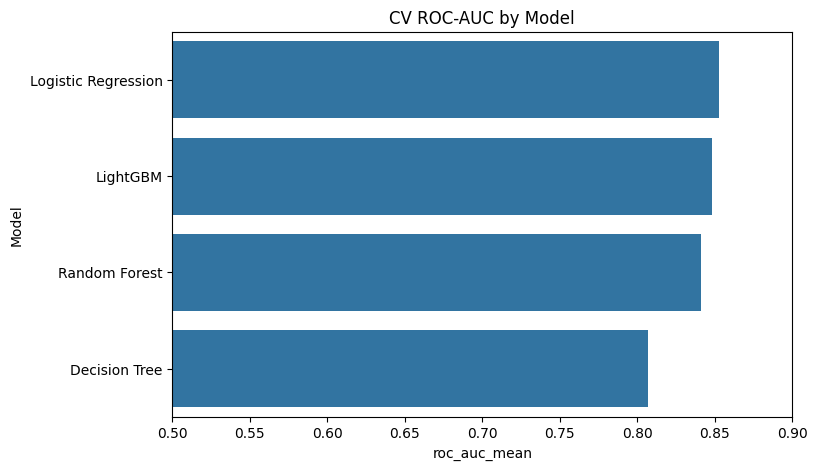

In [ ]:
%pip install -q catboost lightgbm

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05,
                               random_state=42,)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["roc_auc", "recall", "precision", "f1", "accuracy"]

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    row = {"Model": name}
    for m in scoring:
        row[m + "_mean"] = res["test_" + m].mean()
        row[m + "_std"] = res["test_" + m].std()
    rows.append(row)
    print(name, "done")

results = pd.DataFrame(rows).sort_values("roc_auc_mean", ascending=False)
print(results.round(4))

# Bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x="roc_auc_mean", y="Model", data=results)
plt.xlim(0.5, 0.9)
plt.title("CV ROC-AUC by Model")
plt.show()

# ***STAGE 8: Model Evaluation***

Selected model: Logistic Regression
               precision    recall  f1-score   support

   No Disease       0.78      0.81      0.79     29081
Heart Disease       0.76      0.73      0.75     25025

     accuracy                           0.77     54106
    macro avg       0.77      0.77      0.77     54106
 weighted avg       0.77      0.77      0.77     54106



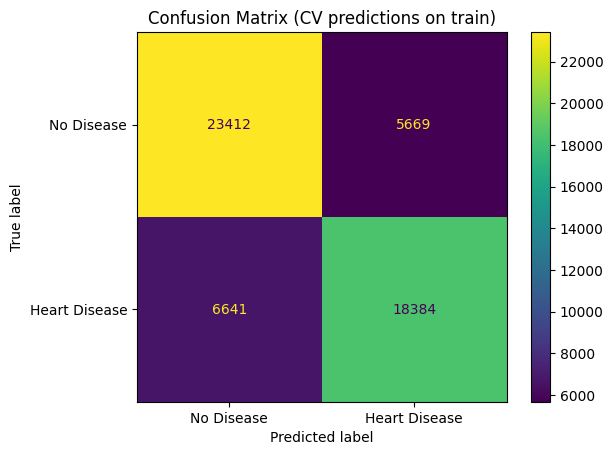

False Negatives (missed patients): 6641
False Positives (false alarms): 5669


In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Choose the highest train CV ROC-AUC from Stage 7
best_name = results.iloc[0]["Model"]
print("Selected model:", best_name)
best_pipe = Pipeline([("prep", preprocessor), ("model", models[best_name])])

y_pred_cv = cross_val_predict(best_pipe, X_train, y_train, cv=cv)

print(classification_report(y_train, y_pred_cv, target_names=["No Disease", "Heart Disease"]))

cm = confusion_matrix(y_train, y_pred_cv)
ConfusionMatrixDisplay(cm, display_labels=["No Disease", "Heart Disease"]).plot()
plt.title("Confusion Matrix (CV predictions on train)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print("False Negatives (missed patients):", fn)
print("False Positives (false alarms):", fp)

# False Negative = model predicts that the person does not have any disease, but they actually do (dangerous).
# Therefore, we give more importance to Recall.

# ***STAGE 9: LR Tuning and Selected Model Threshold***

In [10]:
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.metrics import precision_score, recall_score

# Original LR score
orig_auc = results[results["Model"] == "Logistic Regression"]["roc_auc_mean"].values[0]
orig_std = results[results["Model"] == "Logistic Regression"]["roc_auc_std"].values[0]

lr_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

# Search ranges
# class_weight: Using 'balanced' may increase recall due to data distribution adjustment.
lr_params = {
    "model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    "model__class_weight": [None, "balanced"]
}

grid = GridSearchCV(lr_pipe, lr_params, scoring="roc_auc", cv=cv, n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 4))

# Inspect the results of all combinations.
grid_df = pd.DataFrame(grid.cv_results_)
print(grid_df[["param_model__C", "param_model__class_weight",
               "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False).round(4))

# Tuned vs original comparison
print("Original CV ROC-AUC:", round(orig_auc, 4), "+/-", round(orig_std, 4))
print("Tuned CV ROC-AUC   :", round(grid.best_score_, 4))
print("Improvement        :", round(grid.best_score_ - orig_auc, 4))

# THRESHOLD TUNING
best_lr = grid.best_estimator_
selected_pipe = best_lr if best_name == "Logistic Regression" else best_pipe
print("Threshold tuning for:", best_name)
train_proba = cross_val_predict(selected_pipe, X_train, y_train, cv=cv,
                                method="predict_proba")[:, 1]

print("Threshold  Recall  Precision  F1")
thr_rows = []
for t in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:
    pred_t = (train_proba >= t).astype(int)
    r = recall_score(y_train, pred_t)
    p = precision_score(y_train, pred_t)
    f = f1_score(y_train, pred_t)
    thr_rows.append([t, r, p, f])
    print(t, round(r, 3), round(p, 3), round(f, 3))

# Choose the highest precision among thresholds with recall >= 0.80
chosen_threshold = None
best_precision = 0
for row in thr_rows:
    t, r, p, f = row
    if r >= 0.80 and p > best_precision:
        best_precision = p
        chosen_threshold = t
if chosen_threshold is None:
    raise ValueError("No tested threshold reached recall of 0.80")
print("Chosen threshold:", chosen_threshold)

Fitting 5 folds for each of 14 candidates, totalling 70 fits
Best params: {'model__C': 0.3, 'model__class_weight': None}
Best CV ROC-AUC: 0.8525
    param_model__C param_model__class_weight  mean_test_score  std_test_score
6             0.30                      None           0.8525          0.0021
7             0.30                  balanced           0.8525          0.0021
9             1.00                  balanced           0.8525          0.0021
11            3.00                  balanced           0.8525          0.0021
13           10.00                  balanced           0.8525          0.0021
10            3.00                      None           0.8525          0.0021
8             1.00                      None           0.8525          0.0021
12           10.00                      None           0.8525          0.0021
4             0.10                      None           0.8525          0.0021
2             0.03                      None           0.8525          0.00

# ***STAGE 10: Final Evaluation***

=== Default threshold 0.5 ===
Accuracy : 0.7688
Precision: 0.7661
Recall   : 0.7198
F1       : 0.7423
ROC-AUC  : 0.8497
=== Chosen threshold 0.4 ===
Accuracy : 0.7604
Precision: 0.714
Recall   : 0.8041
F1       : 0.7564
               precision    recall  f1-score   support

   No Disease       0.81      0.72      0.76      7270
Heart Disease       0.71      0.80      0.76      6257

     accuracy                           0.76     13527
    macro avg       0.76      0.76      0.76     13527
 weighted avg       0.77      0.76      0.76     13527

Baseline test accuracy: 0.5374


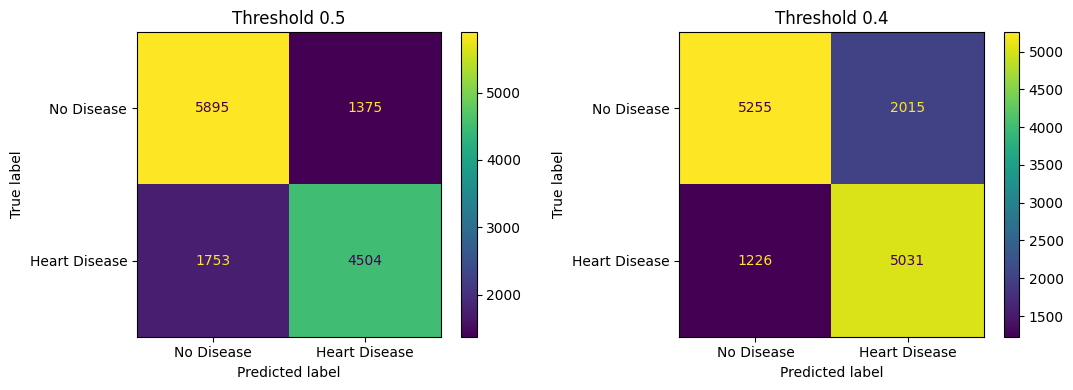

Missed patients (FN): 1226
False alarms (FP): 2015


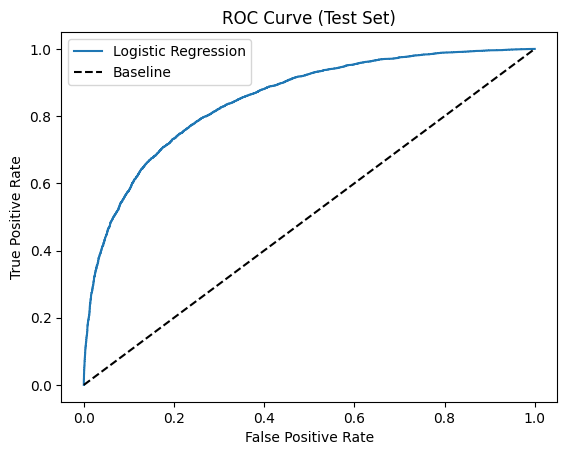

                                          feature  coefficient  odds_ratio
12                      bin__previous_heart_event        0.907       2.477
0                                        num__age        0.745       2.106
10                              bin__hypertension        0.649       1.913
9                                   bin__diabetes        0.631       1.880
13                           bin__exercise_angina        0.555       1.742
11                            bin__family_history        0.478       1.613
24                        cat__st_slope_Upsloping       -0.445       0.641
20                        cat__resting_ecg_Normal       -0.397       0.672
14                                cat__sex_Female       -0.372       0.689
18                      cat__smoking_status_Never       -0.354       0.702
7                              num__st_depression        0.330       1.391
22                      cat__st_slope_Downsloping        0.307       1.359
3                        

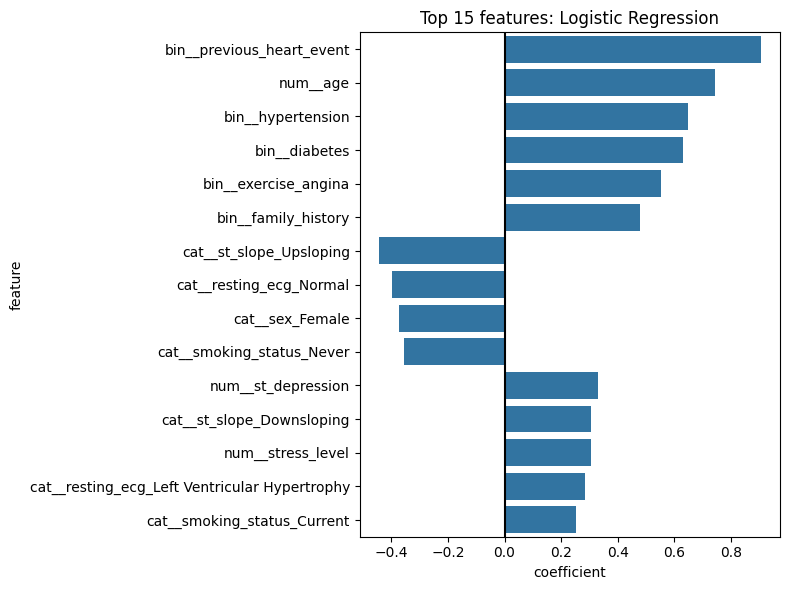

In [11]:
from sklearn.metrics import roc_curve

# Fit the final model on the training set
final_model = selected_pipe
final_model.fit(X_train, y_train)

y_proba = final_model.predict_proba(X_test)[:, 1]

# A) Default threshold of 0.5
y_pred_default = (y_proba >= 0.5).astype(int)

# B) Custom threshold chosen from the training set
y_pred_tuned = (y_proba >= chosen_threshold).astype(int)

print("=== Default threshold 0.5 ===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_default), 4))
print("Precision:", round(precision_score(y_test, y_pred_default), 4))
print("Recall   :", round(recall_score(y_test, y_pred_default), 4))
print("F1       :", round(f1_score(y_test, y_pred_default), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_proba), 4))

print("=== Chosen threshold", chosen_threshold, "===")
print("Accuracy :", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_tuned), 4))
print("Recall   :", round(recall_score(y_test, y_pred_tuned), 4))
print("F1       :", round(f1_score(y_test, y_pred_tuned), 4))

print(classification_report(y_test, y_pred_tuned, target_names=["No Disease", "Heart Disease"]))

# Baseline comparison (Stage 6 dummy)
dummy_test_pred = dummy.predict(X_test)
print("Baseline test accuracy:", round(accuracy_score(y_test, dummy_test_pred), 4))

# Confusion matrix for both thresholds
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_default),
                       display_labels=["No Disease", "Heart Disease"]).plot(ax=axes[0])
axes[0].set_title("Threshold 0.5")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_tuned),
                       display_labels=["No Disease", "Heart Disease"]).plot(ax=axes[1])
axes[1].set_title("Threshold " + str(chosen_threshold))
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_tuned).ravel()
print("Missed patients (FN):", fn)
print("False alarms (FP):", fp)

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, label=best_name)
plt.plot([0, 1], [0, 1], "k--", label="Baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Test Set)")
plt.legend()
plt.show()

# Feature importance for the selected model
feature_names = final_model.named_steps["prep"].get_feature_names_out()
trained_model = final_model.named_steps["model"]

if best_name == "Logistic Regression":
    values = trained_model.coef_[0]
    imp_df = pd.DataFrame({"feature": feature_names, "coefficient": values})
    imp_df["odds_ratio"] = np.exp(imp_df["coefficient"])
    imp_df["abs_value"] = imp_df["coefficient"].abs()
    imp_df = imp_df.sort_values("abs_value", ascending=False).head(15)
    print(imp_df[["feature", "coefficient", "odds_ratio"]].round(3))
    plt.figure(figsize=(8, 6))
    sns.barplot(x="coefficient", y="feature", data=imp_df)
    plt.axvline(0, color="black")
else:
    values = trained_model.feature_importances_
    imp_df = pd.DataFrame({"feature": feature_names, "importance": values})
    imp_df = imp_df.sort_values("importance", ascending=False).head(15)
    print(imp_df[["feature", "importance"]].round(3))
    plt.figure(figsize=(8, 6))
    sns.barplot(x="importance", y="feature", data=imp_df)

plt.title("Top 15 features: " + best_name)
plt.tight_layout()
plt.show()

In [12]:
# ===== Final cell in Colab (after Stage 10) =====
import joblib
import sklearn
from importlib.metadata import version
from google.colab import files

bundle = {
    "model": final_model,                 # Preprocessing pipeline + selected estimator
    "threshold": chosen_threshold,        # Tuned threshold based on CV on train
    "columns": X_train.columns.tolist(),  # Ordered input columns
    "sklearn_version": sklearn.__version__,
    "model_name": best_name,
    "catboost_version": version("catboost"),
    "lightgbm_version": version("lightgbm")
}

joblib.dump(bundle, "heart_model_18_features.pkl")
print("Saved model:", best_name, "with", len(bundle["columns"]), "columns")
print("Saved. Threshold:", chosen_threshold)
print("sklearn version:", sklearn.__version__)

files.download("heart_model_18_features.pkl")

Saved model: Logistic Regression with 20 columns
Saved. Threshold: 0.4
sklearn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>